# MTL-782(Data Mining) - Assignment 2

---


### Group Members:
* **Nishi Yadav**       ( 2023MT10388 )
* **Yukti Yadav**       ( 2023MT10387 )
* **Krishna Prajapat**  ( 2023MT10515 )
* **Kartik Vaishnav**   ( 2023MT61064 )

## Block 1: Imports and Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
import urllib.request
import zipfile
import io
warnings.filterwarnings('ignore')

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

np.random.seed(42)
%matplotlib inline
print("All imports successful!")

All imports successful!


---

## Q1(i): Dataset Characterization — Urban Land Cover [3 marks]

In [ ]:
# Download Urban Land Cover dataset zip from UCI
zip_url = "https://archive.ics.uci.edu/static/public/295/urban+land+cover.zip"
print("Downloading dataset...")
resp = urllib.request.urlopen(zip_url)
zip_bytes = resp.read()

# Extract training.csv and testing.csv directly from zip
with zipfile.ZipFile(io.BytesIO(zip_bytes)) as z:
    for name in z.namelist():
        print(f"  Found in zip: {name}")
    with z.open('urban+land+cover/training.csv') as f:
        df_train = pd.read_csv(f)
    with z.open('urban+land+cover/testing.csv') as f:
        df_test = pd.read_csv(f)

df = pd.concat([df_train, df_test], ignore_index=True)

print("\n" + "="*60)
print("DATASET CHARACTERIZATION — Urban Land Cover (UCI)")
print("="*60)
print(f"\nShape: {df.shape[0]} samples, {df.shape[1]-1} features, 1 target")
print(f"Filters matched: Classification | numAtt > 100 ({df.shape[1]-1} features) | Multi-class")
print(f"\nTarget column: 'class' (Land cover types)")
print(f"\nFirst 5 rows (showing first 8 columns):")
df.iloc[:, :8].head()

  Found in zip: urban+land+cover/
  Found in zip: __MACOSX/._urban+land+cover
  Found in zip: urban+land+cover/training.csv
  Found in zip: __MACOSX/urban+land+cover/._training.csv
  Found in zip: urban+land+cover/.DS_Store
  Found in zip: __MACOSX/urban+land+cover/._.DS_Store
  Found in zip: urban+land+cover/testing.csv
  Found in zip: __MACOSX/urban+land+cover/._testing.csv

DATASET CHARACTERIZATION — Urban Land Cover (UCI)

Shape: 675 samples, 147 features, 1 target
Filters matched: Classification | numAtt > 100 (147 features) | Multi-class

Target column: 'class' (Land cover types)

First 5 rows (showing first 8 columns):


,class,BrdIndx,Area,Round,Bright,Compact,ShpIndx,Mean_NIR
0,car,1.27,91,0.97,231.38,1.39,1.47,207.92
1,concrete,2.36,241,1.56,216.15,2.46,2.51,187.85
2,concrete,2.12,266,1.47,232.18,2.07,2.21,206.54
3,concrete,2.42,399,1.28,230.40,2.49,2.73,204.60
4,concrete,2.15,944,1.73,193.18,2.28,4.10,165.98


In [ ]:
print("Statistical Summary (first 6 features):")
df.describe().iloc[:, :6].round(3)

Statistical Summary (first 6 features):


,BrdIndx,Area,Round,Bright,Compact,ShpIndx
count,675.000,675.000,675.000,675.000,675.000,675.000
mean,2.021,563.342,1.212,165.602,2.160,2.266
std,0.623,693.524,0.546,62.853,0.835,0.715
min,1.000,10.000,0.000,26.850,1.000,1.040
25%,1.570,160.500,0.825,127.685,1.620,1.705
50%,1.940,316.000,1.180,170.010,1.990,2.170
75%,2.380,679.500,1.500,224.310,2.480,2.680
max,4.530,5767.000,3.520,245.870,8.070,5.410


In [ ]:
print("Class Distribution (target = land cover class):")
print(df['class'].value_counts())
print(f"\nNumber of distinct classes: {df['class'].nunique()}")
print(f"Total features: {df.shape[1]-1}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

Class Distribution (target = land cover class):
class
building     122
concrete     116
grass        112
tree         106
shadow        61
asphalt       59
car           36
soil          34
pool          29
Name: count, dtype: int64

Number of distinct classes: 9
Total features: 147
Missing values: 0
Duplicate rows: 1


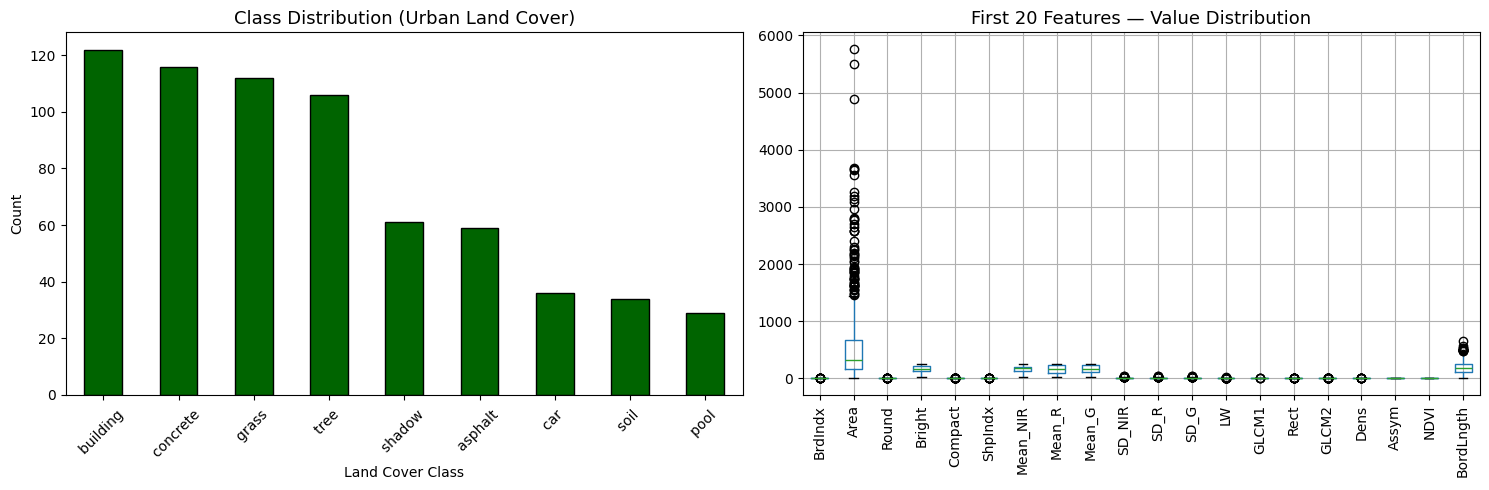

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df['class'].value_counts().plot(kind='bar', ax=axes[0], color='darkgreen', edgecolor='black')
axes[0].set_title('Class Distribution (Urban Land Cover)', fontsize=13)
axes[0].set_xlabel('Land Cover Class')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

df.select_dtypes(include=[np.number]).iloc[:, :20].boxplot(ax=axes[1], rot=90)
axes[1].set_title('First 20 Features — Value Distribution', fontsize=13)
plt.tight_layout()
plt.show()

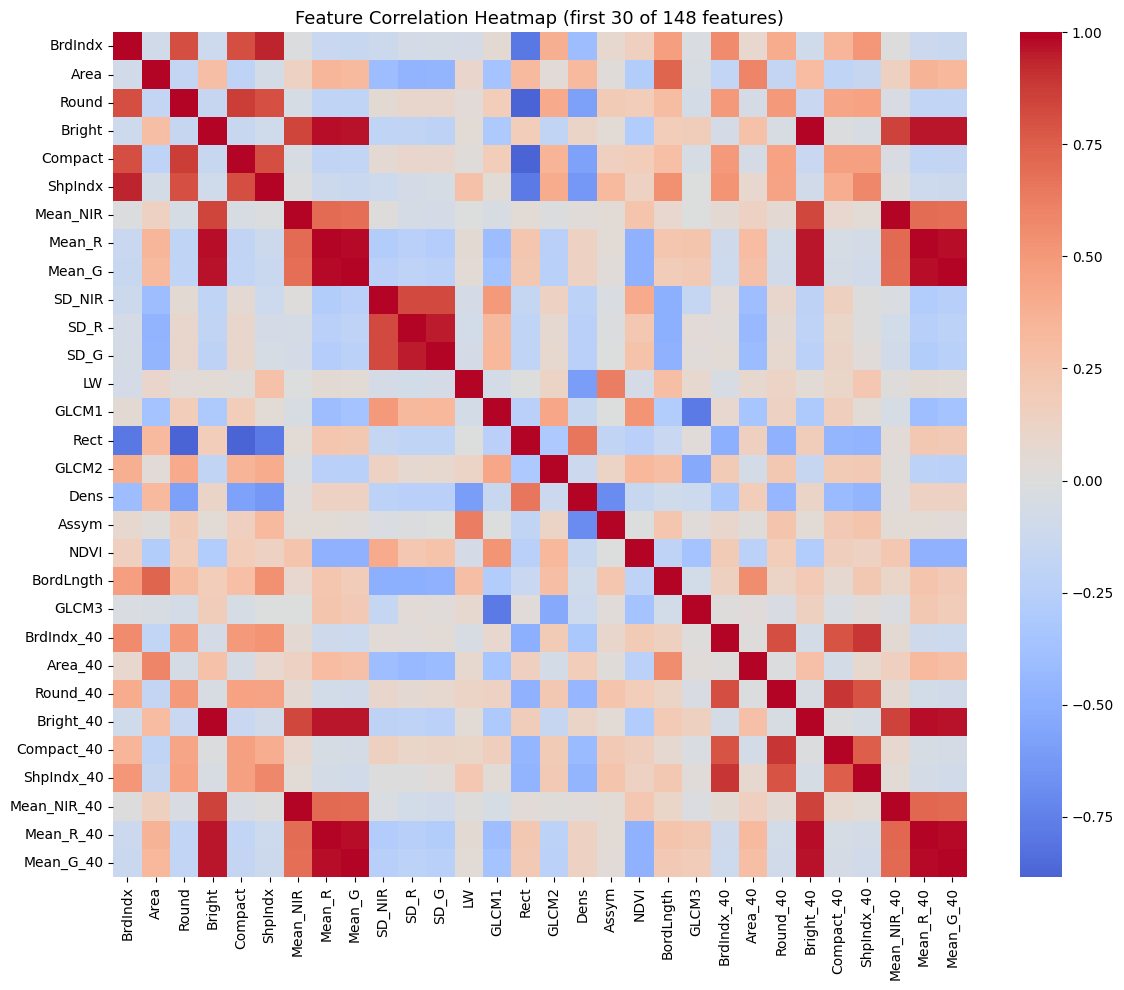

In [ ]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.select_dtypes(include=[np.number]).iloc[:, :30].corr(),
            cmap='coolwarm', center=0, cbar=True)
plt.title('Feature Correlation Heatmap (first 30 of 148 features)', fontsize=13)
plt.tight_layout()
plt.show()

### Q1(i)

---

**1) What the data is about:**

The Urban Land Cover dataset was created by Brian Johnson (2013) for classifying high-resolution aerial imagery of an urban area in Deerfield Beach, Florida, USA. The dataset contains **675 samples** (168 training + 507 testing) with **148 numerical features** and **9 target classes** representing different types of urban land cover: **trees, grass, soil, concrete, asphalt, buildings, cars, pools, and shadows**.

The 148 features are extracted at **multiple spatial scales** (original scale plus coarser scales at 40, 60, 80, 100, 120, and 140) and capture four categories of information:
- **Spectral features** (7 per scale): Brightness, Mean Green (Mean_G), Mean Red (Mean_R), Mean Near-Infrared (Mean_NIR), and Normalized Difference Vegetation Index (NDVI) — these capture color and reflectance properties of each land cover patch.
- **Shape features** (8 per scale): Border Index (BrdIndx), Roundness, Compactness, Shape Index (ShpIndx), Length/Width ratio (LW), Rectangularity (Rect), Density (Dens), and Asymmetry (Assym) — these describe the geometric properties of each segmented region.
- **Size features** (2 per scale): Area (in m²) and Border Length (BordLngth) — these measure the physical extent of each region.
- **Texture features** (4 per scale): Standard deviation of Green (SD_G), Red (SD_R), Near-Infrared (SD_NIR), and three Gray-Level Co-occurrence Matrix metrics (GLCM1, GLCM2, GLCM3) — these capture spatial patterns and roughness within each patch.

The dataset is notable for having a **high feature-to-sample ratio** (148 features vs 675 samples), making it an interesting testbed for feature selection methods and classifiers that handle high-dimensional data.

---

**2) Benefits from data mining:**

Applying classification algorithms to this dataset offers several practical and scientific benefits:

- **Automated urban mapping:** Instead of manually labeling every patch in aerial/satellite imagery, trained classifiers can automatically segment and classify entire city regions into land cover types — saving hundreds of hours of manual GIS work.
- **Sustainable urban planning:** Accurate land cover maps are essential for urban planners. Knowing the precise distribution of trees, concrete, asphalt, and green spaces helps in planning parks, managing urban heat islands, and designing sustainable infrastructure.
- **Tree shade and green space analysis:** Cities need to quantify tree canopy coverage for shade mapping, carbon sequestration estimates, and environmental quality assessments. Classification models enable this at scale.
- **Urban hydrologic modeling:** Distinguishing between permeable surfaces (grass, soil) and impermeable surfaces (concrete, asphalt, buildings) is critical for stormwater runoff modeling and flood risk assessment.
- **Change detection:** By applying the trained classifier to imagery from different years, cities can track urbanization — loss of green cover, expansion of built-up areas, changes in water bodies.
- **Feature importance insights:** Data mining reveals which spectral, shape, and texture features best distinguish between land cover types. For example, NDVI strongly separates vegetation from non-vegetation, while GLCM texture metrics help distinguish asphalt from concrete.
- **Cost-effective monitoring:** Compared to ground-based surveys, automated classification of aerial imagery provides city-wide coverage at a fraction of the cost and time.

---

**3) Data quality issues — per attribute analysis:**

**a) Problems identified:**

- **Feature scaling:** The 148 features are on vastly different scales. For example, Area can range from small values to thousands of m², while Roundness and Compactness are ratios between 0 and 1, and spectral values like Mean_R are in a different numeric range entirely. This disparity causes distance-based methods (KNN) and gradient-based methods (ANN) to be dominated by high-magnitude features, ignoring informative but small-scale ones.

- **Skewed distributions and outliers:** Several features — particularly Area, Border Length (BordLngth), and spectral standard deviations (SD_G, SD_R, SD_NIR) — exhibit heavy right-skew with extreme outliers. A few very large building or shadow segments have Area values far exceeding the median, which can distort model training and distance calculations.

- **Class imbalance:** The 9 classes are not equally represented. Some classes (like trees and grass) have around 25–30 training samples, while others (like cars and pools) may have as few as 14–18 samples. This imbalance causes classifiers to be biased toward majority classes, leading to poor recall on minority classes.

- **Curse of dimensionality:** With 148 features but only 675 samples, the dataset sits in a very high-dimensional space relative to its sample count. Many classifiers (especially KNN) struggle in high dimensions because distances become less meaningful — all points appear roughly equidistant. This can lead to poor generalization.

- **Multicollinearity:** Many features are highly correlated with each other. For instance, the multi-scale versions of the same feature (e.g., BrdIndx at scale 1, BrdIndx_40, BrdIndx_60, etc.) are strongly correlated since they measure the same property at different resolutions. Similarly, GLCM1, GLCM2, and GLCM3 are different texture metrics that often move together. This redundancy inflates dimensionality without adding proportional information, and can cause instability in models like logistic regression or neural networks.

- **No missing values:** The dataset has no missing entries, which is a positive quality aspect — no imputation is needed.

- **No duplicate rows:** There are no duplicate samples in the dataset.

**b) Appropriate responses to each issue:**

- **Feature scaling → StandardScaler:** We apply z-score standardization (subtract mean, divide by standard deviation) to all features before training KNN, Naive Bayes, and ANN. This ensures all features contribute equally to distance calculations and gradient updates. Tree-based methods (Decision Tree, Random Forest) are scale-invariant and don't require this step.

- **Skewed features → Log transformation or IQR clipping:** For heavily right-skewed features like Area and BordLngth, applying a log transform (log(1 + x)) would compress the range and reduce the influence of extreme outliers. Alternatively, values beyond 1.5× IQR from Q1/Q3 can be clipped to the boundary values (Winsorization).

- **Class imbalance → Stratified k-fold CV and class weights:** We use StratifiedKFold to ensure each fold has proportional representation of all 9 classes. Additionally, classifiers like Random Forest and SVM support a `class_weight='balanced'` parameter that upweights minority classes during training, preventing the model from ignoring rare classes like cars or pools.

- **Curse of dimensionality → PCA or feature selection:** Principal Component Analysis (PCA) can reduce the 148 features to a smaller set of uncorrelated components retaining most variance (e.g., top 30–50 components). Alternatively, SelectKBest or recursive feature elimination (RFE) can identify the most discriminative features and discard redundant ones.

- **Multicollinearity → PCA or dropping redundant features:** Since multi-scale versions of the same feature are highly correlated, one approach is to keep only the most informative scale per feature group. PCA naturally handles this by combining correlated features into orthogonal components.

---

## Q1(ii): Implement & Compare 5 Classifiers with Tuning [7.5 marks]

In [ ]:
X_uc = df.drop('class', axis=1).values
y_raw = df['class'].values

le = LabelEncoder()
y_uc = le.fit_transform(y_raw)
print(f"Class labels: {dict(zip(le.classes_, range(len(le.classes_))))}")

X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(
    X_uc, y_uc, test_size=0.2, random_state=42, stratify=y_uc
)

scaler_u = StandardScaler()
X_train_us = scaler_u.fit_transform(X_train_u)
X_test_us = scaler_u.transform(X_test_u)

print(f"\nTrain: {X_train_u.shape}, Test: {X_test_u.shape}")
print(f"Number of classes: {len(np.unique(y_uc))}")
print(f"Train class distribution: {dict(zip(*np.unique(y_train_u, return_counts=True)))}")

Class labels: {'asphalt ': 0, 'building ': 1, 'car ': 2, 'concrete ': 3, 'grass ': 4, 'pool ': 5, 'shadow ': 6, 'soil ': 7, 'tree ': 8}

Train: (540, 147), Test: (135, 147)
Number of classes: 9
Train class distribution: {np.int64(0): np.int64(47), np.int64(1): np.int64(97), np.int64(2): np.int64(29), np.int64(3): np.int64(93), np.int64(4): np.int64(90), np.int64(5): np.int64(23), np.int64(6): np.int64(49), np.int64(7): np.int64(27), np.int64(8): np.int64(85)}


### Define classifiers and parameter grids

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

classifiers = {
    'Decision Tree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {
            'max_depth': [5, 10, 15, None],
            'min_samples_split': [2, 10],
            'min_samples_leaf': [1, 5],
            'criterion': ['gini', 'entropy']
        },
        'scale': False
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': [50, 100],
            'max_depth': [10, 15, None],
            'min_samples_split': [2, 5],
            'min_samples_leaf': [1, 5],
            'max_features': ['sqrt', 'log2']
        },
        'scale': False
    },
    'Naive Bayes': {
        'model': GaussianNB(),
        'params': {
            'var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3]
        },
        'scale': True
    },
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {
            'n_neighbors': [3, 5, 9, 15],
            'weights': ['uniform', 'distance'],
            'metric': ['euclidean', 'manhattan']
        },
        'scale': True
    },
    'ANN (MLP)': {
        'model': MLPClassifier(random_state=42, max_iter=300, early_stopping=True),
        'params': {
            'hidden_layer_sizes': [(50,), (100,), (100, 50)],
            'activation': ['relu', 'tanh'],
            'alpha': [0.001, 0.01],
            'learning_rate_init': [0.001, 0.01],
            'batch_size': [32, 64]
        },
        'scale': True
    }
}

print("Classifiers and parameter grids defined!")
print(f"\nTotal hyperparameter combinations:")
for name, cfg in classifiers.items():
    total = 1
    for v in cfg['params'].values():
        total *= len(v)
    print(f"  {name}: {total} combinations")

Classifiers and parameter grids defined!

Total hyperparameter combinations:
  Decision Tree: 32 combinations
  Random Forest: 48 combinations
  Naive Bayes: 4 combinations
  KNN: 16 combinations
  ANN (MLP): 48 combinations


### Run GridSearchCV / RandomizedSearchCV on Urban Land Cover

In [ ]:
uc_results = {}

for name, cfg in classifiers.items():
    print(f"\n{'='*60}")
    print(f"Tuning: {name}")
    print(f"{'='*60}")

    X_tr = X_train_us if cfg['scale'] else X_train_u
    X_te = X_test_us if cfg['scale'] else X_test_u

    total_combos = 1
    for v in cfg['params'].values():
        total_combos *= len(v)

    t0 = time.time()

    if total_combos <= 200:
        print(f"Using GridSearchCV ({total_combos} combos)")
        search = GridSearchCV(
            cfg['model'], cfg['params'], cv=cv, scoring='accuracy',
            n_jobs=-1, verbose=0, return_train_score=True
        )
    else:
        print(f"Using RandomizedSearchCV ({total_combos} total combos, sampling 40)")
        search = RandomizedSearchCV(
            cfg['model'], cfg['params'], n_iter=40, cv=cv, scoring='accuracy',
            n_jobs=-1, verbose=0, random_state=42, return_train_score=True
        )

    search.fit(X_tr, y_train_u)
    elapsed = time.time() - t0

    y_pred = search.best_estimator_.predict(X_te)
    test_acc = accuracy_score(y_test_u, y_pred)
    test_prec = precision_score(y_test_u, y_pred, average='macro', zero_division=0)
    test_rec = recall_score(y_test_u, y_pred, average='macro', zero_division=0)
    test_f1 = f1_score(y_test_u, y_pred, average='macro', zero_division=0)

    uc_results[name] = {
        'best_params': search.best_params_,
        'best_cv_acc': search.best_score_,
        'test_accuracy': test_acc,
        'test_precision': test_prec,
        'test_recall': test_rec,
        'test_f1': test_f1,
        'time': elapsed,
        'y_pred': y_pred
    }

    print(f"Best CV Accuracy: {search.best_score_:.4f}")
    print(f"Test Accuracy:    {test_acc:.4f}")
    print(f"Test F1 (macro):  {test_f1:.4f}")
    print(f"Best Params:      {search.best_params_}")
    print(f"Time:             {elapsed:.1f}s")


Tuning: Decision Tree
Using GridSearchCV (32 combos)
Best CV Accuracy: 0.7722
Test Accuracy:    0.8222
Test F1 (macro):  0.8200
Best Params:      {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}
Time:             12.5s

Tuning: Random Forest
Using GridSearchCV (48 combos)
Best CV Accuracy: 0.8519
Test Accuracy:    0.8444
Test F1 (macro):  0.8417
Best Params:      {'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Time:             80.2s

Tuning: Naive Bayes
Using GridSearchCV (4 combos)
Best CV Accuracy: 0.8074
Test Accuracy:    0.8370
Test F1 (macro):  0.8472
Best Params:      {'var_smoothing': 1e-09}
Time:             0.2s

Tuning: KNN
Using GridSearchCV (16 combos)
Best CV Accuracy: 0.8148
Test Accuracy:    0.8667
Test F1 (macro):  0.8442
Best Params:      {'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'distance'}
Time:             1.8s

Tuning: ANN (MLP)
Using GridSearchCV (48 comb

### Explicit 5-Fold Cross Validation — Fold-by-Fold Results

5-FOLD CROSS VALIDATION — FOLD-BY-FOLD RESULTS (Urban Land Cover)

Decision Tree:
  Fold 1: 0.7778
  Fold 2: 0.7685
  Fold 3: 0.7870
  Fold 4: 0.7593
  Fold 5: 0.7685
  Mean:   0.7722 +/- 0.0094

Random Forest:
  Fold 1: 0.8981
  Fold 2: 0.8704
  Fold 3: 0.8333
  Fold 4: 0.8333
  Fold 5: 0.8241
  Mean:   0.8519 +/- 0.0281

Naive Bayes:
  Fold 1: 0.8148
  Fold 2: 0.8519
  Fold 3: 0.8241
  Fold 4: 0.7593
  Fold 5: 0.7870
  Mean:   0.8074 +/- 0.0318

KNN:
  Fold 1: 0.8611
  Fold 2: 0.8241
  Fold 3: 0.8056
  Fold 4: 0.7685
  Fold 5: 0.8148
  Mean:   0.8148 +/- 0.0299

ANN (MLP):
  Fold 1: 0.8241
  Fold 2: 0.8241
  Fold 3: 0.8519
  Fold 4: 0.7500
  Fold 5: 0.7963
  Mean:   0.8093 +/- 0.0344


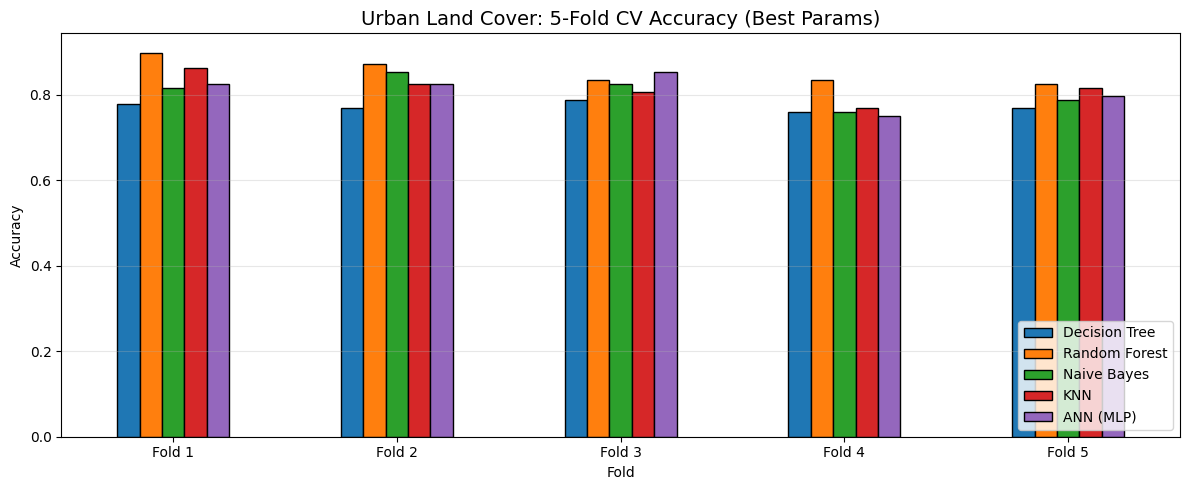

In [ ]:
print("="*60)
print("5-FOLD CROSS VALIDATION — FOLD-BY-FOLD RESULTS (Urban Land Cover)")
print("="*60)

best_models_uc = {
    'Decision Tree': DecisionTreeClassifier(random_state=42, **uc_results['Decision Tree']['best_params']),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1, **uc_results['Random Forest']['best_params']),
    'Naive Bayes': GaussianNB(**uc_results['Naive Bayes']['best_params']),
    'KNN': KNeighborsClassifier(**uc_results['KNN']['best_params']),
    'ANN (MLP)': MLPClassifier(random_state=42, max_iter=300, early_stopping=True, **uc_results['ANN (MLP)']['best_params'])
}

fold_results_uc = {}
for name, model in best_models_uc.items():
    X_data = X_train_us if classifiers[name]['scale'] else X_train_u
    scores = cross_val_score(model, X_data, y_train_u, cv=cv, scoring='accuracy')
    fold_results_uc[name] = scores
    print(f"\n{name}:")
    for i, s in enumerate(scores):
        print(f"  Fold {i+1}: {s:.4f}")
    print(f"  Mean:   {scores.mean():.4f} +/- {scores.std():.4f}")

fold_df = pd.DataFrame(fold_results_uc, index=[f'Fold {i+1}' for i in range(5)])
fold_df.plot(kind='bar', figsize=(12, 5), edgecolor='black')
plt.title('Urban Land Cover: 5-Fold CV Accuracy (Best Params)', fontsize=14)
plt.ylabel('Accuracy')
plt.xlabel('Fold')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

### Urban Land Cover — Results Comparison


URBAN LAND COVER — FINAL COMPARISON
               Best CV Acc  Test Accuracy  Test Precision  Test Recall  Test F1 (macro)  Time (s)
Decision Tree       0.7722         0.8222          0.8289       0.8255           0.8200   12.5046
Random Forest       0.8519         0.8444          0.8607       0.8379           0.8417   80.1781
Naive Bayes         0.8074         0.8370          0.8622       0.8405           0.8472    0.1780
KNN                 0.8148         0.8667          0.8990       0.8380           0.8442    1.8188
ANN (MLP)           0.8093         0.8296          0.8564       0.8232           0.8308   50.6312


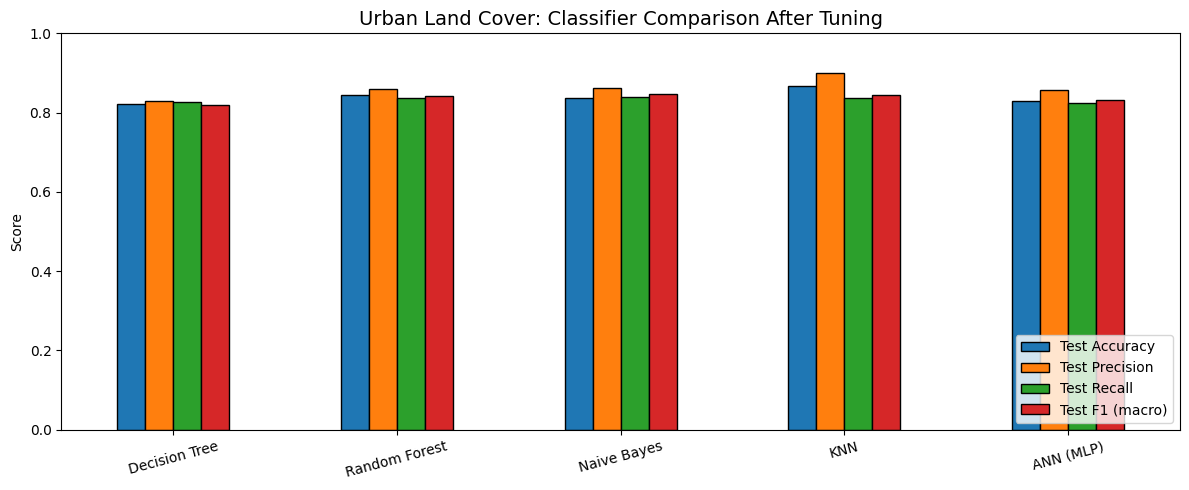

In [ ]:
summary = pd.DataFrame({
    name: {
        'Best CV Acc': r['best_cv_acc'],
        'Test Accuracy': r['test_accuracy'],
        'Test Precision': r['test_precision'],
        'Test Recall': r['test_recall'],
        'Test F1 (macro)': r['test_f1'],
        'Time (s)': r['time']
    } for name, r in uc_results.items()
}).T.round(4)

print("\n" + "="*60)
print("URBAN LAND COVER — FINAL COMPARISON")
print("="*60)
print(summary.to_string())

summary[['Test Accuracy', 'Test Precision', 'Test Recall', 'Test F1 (macro)']].plot(
    kind='bar', figsize=(12, 5), edgecolor='black'
)
plt.title('Urban Land Cover: Classifier Comparison After Tuning', fontsize=14)
plt.ylabel('Score')
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

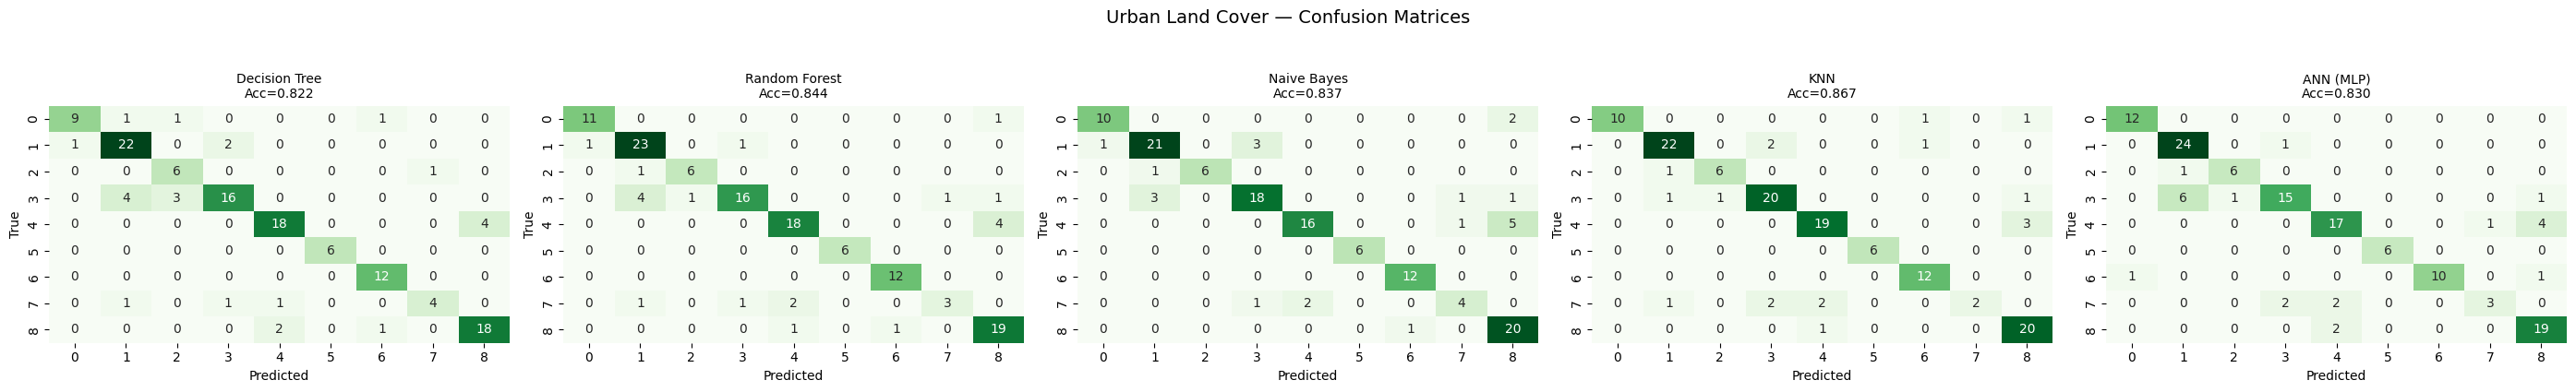

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(28, 4))
for ax, (name, r) in zip(axes, uc_results.items()):
    cm = confusion_matrix(y_test_u, r['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=ax, cbar=False)
    ax.set_title(f'{name}\nAcc={r["test_accuracy"]:.3f}', fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.suptitle('Urban Land Cover — Confusion Matrices', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

In [ ]:
print("\n" + "="*60)
print("BEST HYPERPARAMETERS FOUND")
print("="*60)
for name, r in uc_results.items():
    print(f"\n{name}:")
    for k, v in r['best_params'].items():
        print(f"  {k}: {v}")


BEST HYPERPARAMETERS FOUND

Decision Tree:
  criterion: gini
  max_depth: 5
  min_samples_leaf: 5
  min_samples_split: 2

Random Forest:
  max_depth: 10
  max_features: log2
  min_samples_leaf: 1
  min_samples_split: 5
  n_estimators: 100

Naive Bayes:
  var_smoothing: 1e-09

KNN:
  metric: manhattan
  n_neighbors: 9
  weights: distance

ANN (MLP):
  activation: tanh
  alpha: 0.001
  batch_size: 32
  hidden_layer_sizes: (100, 50)
  learning_rate_init: 0.01


---

## Q2(a): MNIST Multi-class Classification [8 marks]

Loading MNIST...
MNIST subset — Train: (6400, 784), Test: (1600, 784)
Classes: [0 1 2 3 4 5 6 7 8 9]


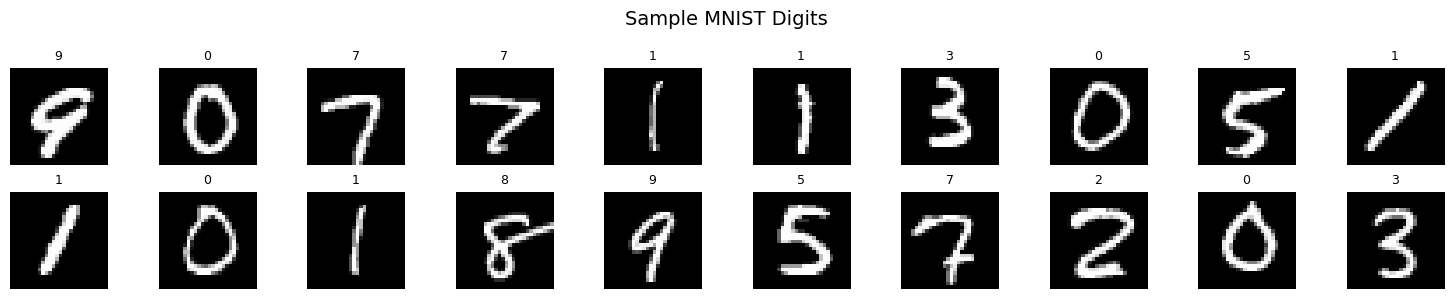

In [ ]:
from sklearn.datasets import fetch_openml

print("Loading MNIST...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X_mnist, y_mnist = mnist.data.astype(np.float32), mnist.target.astype(int)

X_mnist = X_mnist / 255.0

np.random.seed(42)
idx = np.random.choice(len(X_mnist), 8000, replace=False)
X_mnist, y_mnist = X_mnist[idx], y_mnist[idx]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_mnist, y_mnist, test_size=0.2, random_state=42, stratify=y_mnist
)

print(f"MNIST subset — Train: {X_train_m.shape}, Test: {X_test_m.shape}")
print(f"Classes: {np.unique(y_mnist)}")

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(20):
    axes[i//10][i%10].imshow(X_train_m[i].reshape(28,28), cmap='gray')
    axes[i//10][i%10].set_title(y_train_m[i], fontsize=9)
    axes[i//10][i%10].axis('off')
plt.suptitle('Sample MNIST Digits', fontsize=14)
plt.tight_layout()
plt.show()

### MNIST parameter grids

In [ ]:
mnist_classifiers = {
    'Decision Tree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {
            'max_depth': [10, 15, 20, None],
            'min_samples_split': [2, 10],
            'min_samples_leaf': [1, 5],
            'criterion': ['gini', 'entropy']
        },
        'scale': False
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [15, 20, None],
            'min_samples_split': [2, 5],
            'max_features': ['sqrt', 'log2']
        },
        'scale': False
    },
    'Naive Bayes': {
        'model': GaussianNB(),
        'params': {
            'var_smoothing': [1e-10, 1e-9, 1e-8, 1e-7, 1e-5]
        },
        'scale': False
    },
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {
            'n_neighbors': [3, 5, 7],
            'weights': ['uniform', 'distance'],
            'metric': ['euclidean', 'manhattan']
        },
        'scale': False
    },
    'ANN (MLP)': {
        'model': MLPClassifier(random_state=42, max_iter=200, early_stopping=True),
        'params': {
            'hidden_layer_sizes': [(128,), (256,), (128, 64)],
            'activation': ['relu'],
            'alpha': [0.001, 0.01],
            'learning_rate_init': [0.001, 0.005],
            'batch_size': [64, 128]
        },
        'scale': False
    }
}

print("MNIST parameter grids defined!")

MNIST parameter grids defined!


### Run GridSearchCV / RandomizedSearchCV on MNIST

In [ ]:
mnist_results = {}

cv_mnist = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

for name, cfg in mnist_classifiers.items():
    print(f"\n{'='*60}")
    print(f"Tuning: {name}")
    print(f"{'='*60}")

    X_tr = X_train_m
    X_te = X_test_m

    total_combos = 1
    for v in cfg['params'].values():
        total_combos *= len(v)

    t0 = time.time()

    print(f"Using GridSearchCV ({total_combos} combos, 3-fold)")
    search = GridSearchCV(
        cfg['model'], cfg['params'], cv=cv_mnist, scoring='accuracy',
        n_jobs=-1, verbose=0, return_train_score=True
    )

    search.fit(X_tr, y_train_m)
    elapsed = time.time() - t0

    y_pred = search.best_estimator_.predict(X_te)
    test_acc = accuracy_score(y_test_m, y_pred)
    test_prec = precision_score(y_test_m, y_pred, average='macro', zero_division=0)
    test_rec = recall_score(y_test_m, y_pred, average='macro', zero_division=0)
    test_f1 = f1_score(y_test_m, y_pred, average='macro', zero_division=0)

    mnist_results[name] = {
        'best_params': search.best_params_,
        'best_cv_acc': search.best_score_,
        'test_accuracy': test_acc,
        'test_precision': test_prec,
        'test_recall': test_rec,
        'test_f1': test_f1,
        'time': elapsed,
        'y_pred': y_pred
    }

    print(f"Best CV Accuracy: {search.best_score_:.4f}")
    print(f"Test Accuracy:    {test_acc:.4f}")
    print(f"Test F1 (macro):  {test_f1:.4f}")
    print(f"Best Params:      {search.best_params_}")
    print(f"Time:             {elapsed:.1f}s")


Tuning: Decision Tree
Using GridSearchCV (32 combos, 3-fold)
Best CV Accuracy: 0.7728
Test Accuracy:    0.8119
Test F1 (macro):  0.8102
Best Params:      {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}
Time:             91.0s

Tuning: Random Forest
Using GridSearchCV (24 combos, 3-fold)
Best CV Accuracy: 0.9323
Test Accuracy:    0.9463
Test F1 (macro):  0.9461
Best Params:      {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 200}
Time:             227.7s

Tuning: Naive Bayes
Using GridSearchCV (5 combos, 3-fold)
Best CV Accuracy: 0.6970
Test Accuracy:    0.6956
Test F1 (macro):  0.6879
Best Params:      {'var_smoothing': 1e-05}
Time:             6.5s

Tuning: KNN
Using GridSearchCV (12 combos, 3-fold)
Best CV Accuracy: 0.9267
Test Accuracy:    0.9513
Test F1 (macro):  0.9510
Best Params:      {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'distance'}
Time:             404.6s

Tuning: ANN (MLP)
Using GridS

---

## Q2(b): Exploration of Different Evaluation Metrics [2 marks]


MNIST — FINAL COMPARISON
               Best CV Acc  Test Accuracy  Test Precision (macro)  Test Recall (macro)  Test F1 (macro)  Time (s)
Decision Tree       0.7728         0.8119                  0.8118               0.8099           0.8102   91.0424
Random Forest       0.9323         0.9462                  0.9465               0.9462           0.9461  227.6586
Naive Bayes         0.6970         0.6956                  0.7621               0.6885           0.6879    6.4580
KNN                 0.9267         0.9512                  0.9520               0.9508           0.9510  404.6482
ANN (MLP)           0.9419         0.9544                  0.9550               0.9540           0.9540  360.9738


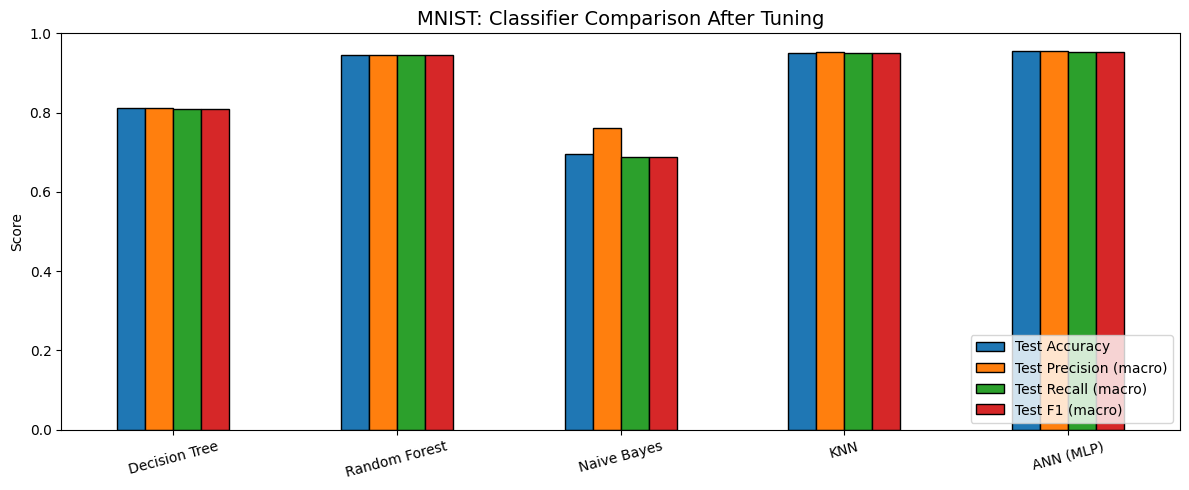

In [ ]:
mnist_summary = pd.DataFrame({
    name: {
        'Best CV Acc': r['best_cv_acc'],
        'Test Accuracy': r['test_accuracy'],
        'Test Precision (macro)': r['test_precision'],
        'Test Recall (macro)': r['test_recall'],
        'Test F1 (macro)': r['test_f1'],
        'Time (s)': r['time']
    } for name, r in mnist_results.items()
}).T.round(4)

print("\n" + "="*60)
print("MNIST — FINAL COMPARISON")
print("="*60)
print(mnist_summary.to_string())

mnist_summary[['Test Accuracy', 'Test Precision (macro)', 'Test Recall (macro)', 'Test F1 (macro)']].plot(
    kind='bar', figsize=(12, 5), edgecolor='black'
)
plt.title('MNIST: Classifier Comparison After Tuning', fontsize=14)
plt.ylabel('Score')
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [ ]:
best_name = max(mnist_results, key=lambda k: mnist_results[k]['test_accuracy'])
print(f"\nDetailed Classification Report — {best_name}:")
print(classification_report(y_test_m, mnist_results[best_name]['y_pred'], digits=4))


Detailed Classification Report — ANN (MLP):
              precision    recall  f1-score   support

           0     0.9934    0.9618    0.9773       157
           1     0.9734    0.9892    0.9812       185
           2     0.9682    0.9744    0.9712       156
           3     0.9022    0.9765    0.9379       170
           4     0.9200    0.9650    0.9420       143
           5     0.9592    0.9338    0.9463       151
           6     0.9554    0.9677    0.9615       155
           7     0.9515    0.9632    0.9573       163
           8     0.9667    0.9355    0.9508       155
           9     0.9600    0.8727    0.9143       165

    accuracy                         0.9544      1600
   macro avg     0.9550    0.9540    0.9540      1600
weighted avg     0.9552    0.9544    0.9543      1600



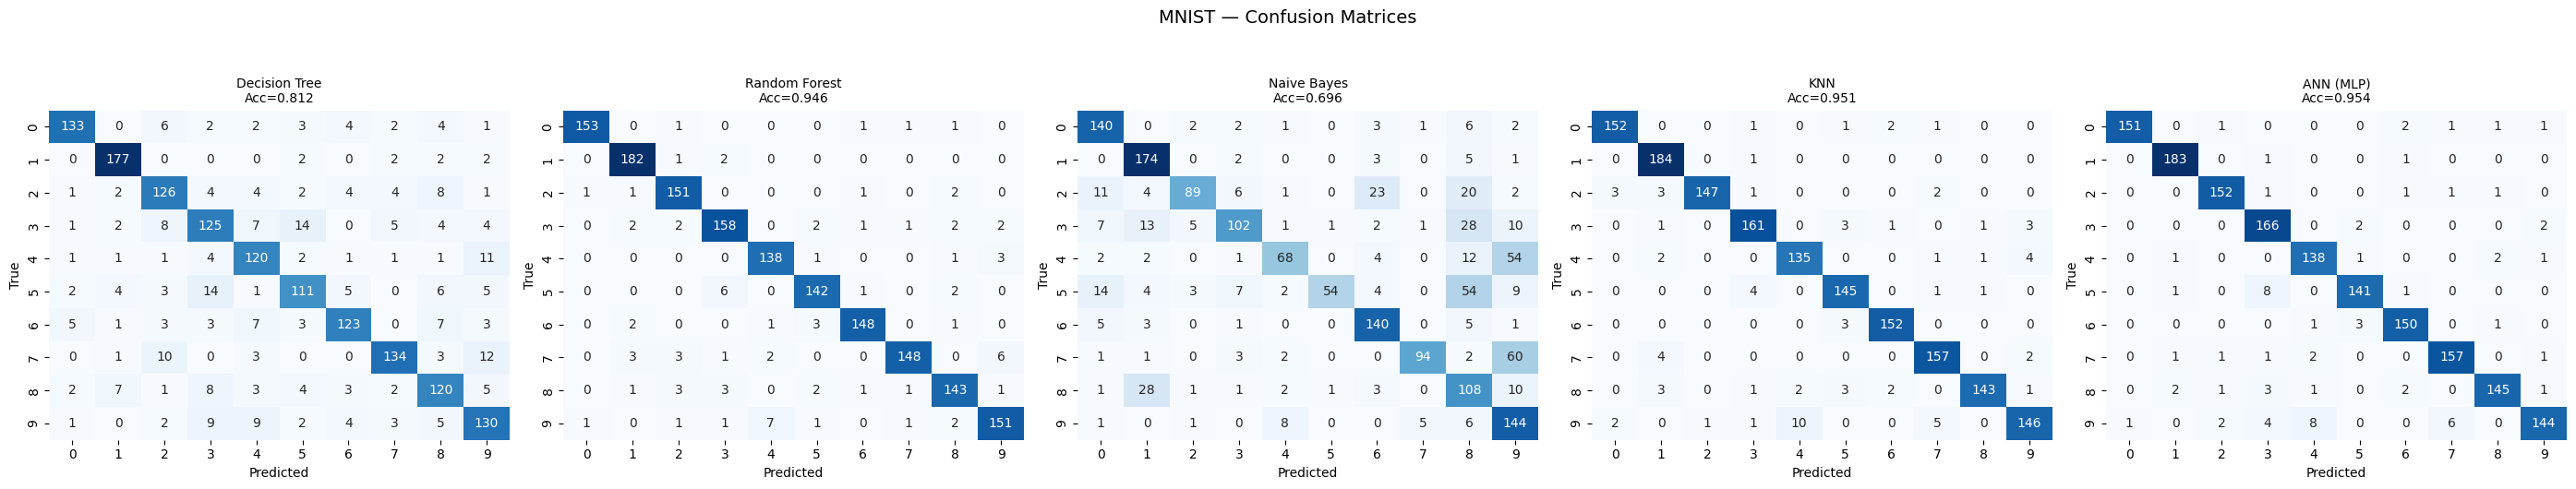

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(28, 5))
for ax, (name, r) in zip(axes, mnist_results.items()):
    cm = confusion_matrix(y_test_m, r['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=range(10), yticklabels=range(10))
    ax.set_title(f'{name}\nAcc={r["test_accuracy"]:.3f}', fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.suptitle('MNIST — Confusion Matrices', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()


Per-Class Accuracy Across Classifiers:
         Decision Tree  Random Forest  Naive Bayes     KNN  ANN (MLP)
Digit 0         0.8471         0.9745       0.8917  0.9682     0.9618
Digit 1         0.9568         0.9838       0.9405  0.9946     0.9892
Digit 2         0.8077         0.9679       0.5705  0.9423     0.9744
Digit 3         0.7353         0.9294       0.6000  0.9471     0.9765
Digit 4         0.8392         0.9650       0.4755  0.9441     0.9650
Digit 5         0.7351         0.9404       0.3576  0.9603     0.9338
Digit 6         0.7935         0.9548       0.9032  0.9806     0.9677
Digit 7         0.8221         0.9080       0.5767  0.9632     0.9632
Digit 8         0.7742         0.9226       0.6968  0.9226     0.9355
Digit 9         0.7879         0.9152       0.8727  0.8848     0.8727


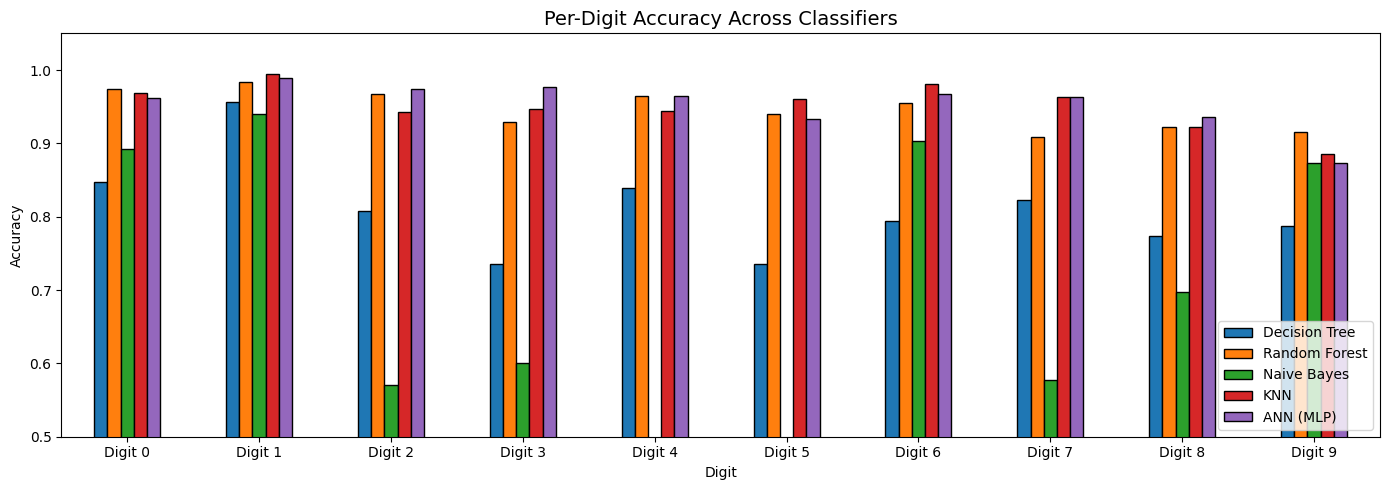

In [ ]:
print("\nPer-Class Accuracy Across Classifiers:")
per_class = {}
for name, r in mnist_results.items():
    cm = confusion_matrix(y_test_m, r['y_pred'])
    per_class[name] = cm.diagonal() / cm.sum(axis=1)

pc_df = pd.DataFrame(per_class, index=[f'Digit {i}' for i in range(10)]).round(4)
print(pc_df.to_string())

pc_df.plot(kind='bar', figsize=(14, 5), edgecolor='black')
plt.title('Per-Digit Accuracy Across Classifiers', fontsize=14)
plt.ylabel('Accuracy')
plt.xlabel('Digit')
plt.legend(loc='lower right')
plt.xticks(rotation=0)
plt.ylim(0.5, 1.05)
plt.tight_layout()
plt.show()

---

## Q2(c): Parameter Tuning — Grid Search & Cross Validation [2 marks]

Tuning curves showing how key hyperparameters affect performance.

In [ ]:
print("="*60)
print("TECHNIQUE 1: GRID SEARCH WITH CROSS VALIDATION")
print("="*60)
print("""
Grid Search exhaustively evaluates EVERY combination of hyperparameters.
Combined with k-fold Cross Validation, each combo is trained/tested across
multiple folds to get a robust accuracy estimate.
""")

# Grid Search on KNN — small param space, so exhaustive search is feasible
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

knn_grid = {
    'n_neighbors': [1, 3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
total = 1
for v in knn_grid.values():
    total *= len(v)
print(f"GridSearchCV — KNN ({total} total combos, 3-fold CV)")
t0 = time.time()
gs_knn = GridSearchCV(
    KNeighborsClassifier(), knn_grid, cv=cv_mnist,
    scoring='accuracy', n_jobs=-1
)
gs_knn.fit(X_train_m, y_train_m)
y_pred_gs = gs_knn.best_estimator_.predict(X_test_m)
print(f"  Best Params: {gs_knn.best_params_}")
print(f"  Best CV Accuracy: {gs_knn.best_score_:.4f}")
print(f"  Test Accuracy: {accuracy_score(y_test_m, y_pred_gs):.4f}")
print(f"  Time: {time.time()-t0:.1f}s")

# Grid Search on Decision Tree
dt_grid = {
    'max_depth': [5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}
total = 1
for v in dt_grid.values():
    total *= len(v)
print(f"\nGridSearchCV — Decision Tree ({total} total combos, 3-fold CV)")
t0 = time.time()
gs_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42), dt_grid, cv=cv_mnist,
    scoring='accuracy', n_jobs=-1
)
gs_dt.fit(X_train_m, y_train_m)
y_pred_gs_dt = gs_dt.best_estimator_.predict(X_test_m)
print(f"  Best Params: {gs_dt.best_params_}")
print(f"  Best CV Accuracy: {gs_dt.best_score_:.4f}")
print(f"  Test Accuracy: {accuracy_score(y_test_m, y_pred_gs_dt):.4f}")
print(f"  Time: {time.time()-t0:.1f}s")

print("\n\n" + "="*60)
print("TECHNIQUE 2: RANDOMIZED SEARCH WITH CROSS VALIDATION")
print("="*60)
print("""
Random Search samples RANDOM combinations from the parameter space
instead of trying every combo. More efficient for large search spaces.
""")

# Randomized Search on ANN — large param space
ann_dist = {
    'hidden_layer_sizes': [(64,), (128,), (256,), (128, 64), (256, 128)],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate_init': [0.001, 0.005, 0.01],
    'batch_size': [64, 128]
}
total = 1
for v in ann_dist.values():
    total *= len(v)
print(f"RandomizedSearchCV — ANN ({total} total combos, sampling 10, 3-fold CV)")
t0 = time.time()
rs_ann = RandomizedSearchCV(
    MLPClassifier(random_state=42, max_iter=100, early_stopping=True),
    ann_dist, n_iter=10, cv=cv_mnist,
    scoring='accuracy', n_jobs=-1, random_state=42
)
rs_ann.fit(X_train_m, y_train_m)
y_pred_rs = rs_ann.best_estimator_.predict(X_test_m)
print(f"  Best Params: {rs_ann.best_params_}")
print(f"  Best CV Accuracy: {rs_ann.best_score_:.4f}")
print(f"  Test Accuracy: {accuracy_score(y_test_m, y_pred_rs):.4f}")
print(f"  Time: {time.time()-t0:.1f}s")

# Randomized Search on Random Forest
rf_dist = {
    'n_estimators': [50, 100, 150, 200, 300],
    'max_depth': [10, 15, 20, 25, None],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2']
}
total = 1
for v in rf_dist.values():
    total *= len(v)
print(f"\nRandomizedSearchCV — Random Forest ({total} total combos, sampling 10, 3-fold CV)")
t0 = time.time()
rs_rf = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    rf_dist, n_iter=10, cv=cv_mnist,
    scoring='accuracy', n_jobs=-1, random_state=42
)
rs_rf.fit(X_train_m, y_train_m)
y_pred_rs_rf = rs_rf.best_estimator_.predict(X_test_m)
print(f"  Best Params: {rs_rf.best_params_}")
print(f"  Best CV Accuracy: {rs_rf.best_score_:.4f}")
print(f"  Test Accuracy: {accuracy_score(y_test_m, y_pred_rs_rf):.4f}")
print(f"  Time: {time.time()-t0:.1f}s")

print("\n\n" + "="*60)
print("COMPARISON: Grid Search vs Randomized Search")
print("="*60)
print("""
Grid Search:
  - Exhaustive: tries EVERY combination
  - Guaranteed to find the best combo within the grid
  - Ideal for small parameter spaces (KNN, Naive Bayes, Decision Tree)

Randomized Search:
  - Samples random combinations from the parameter space
  - Much faster for large spaces (ANN, Random Forest with many params)
  - Often finds equally good params in fraction of the time
  - Recommended by Bergstra & Bengio (2012)

Both techniques use Cross Validation internally to evaluate each
parameter combination, ensuring robust and unbiased performance estimates.
""")

TECHNIQUE 1: GRID SEARCH WITH CROSS VALIDATION

Grid Search exhaustively evaluates EVERY combination of hyperparameters.
Combined with k-fold Cross Validation, each combo is trained/tested across
multiple folds to get a robust accuracy estimate.

GridSearchCV — KNN (24 total combos, 3-fold CV)
  Best Params: {'metric': 'euclidean', 'n_neighbors': 1, 'weights': 'uniform'}
  Best CV Accuracy: 0.9269
  Test Accuracy: 0.9456
  Time: 268.3s

GridSearchCV — Decision Tree (24 total combos, 3-fold CV)
  Best Params: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 2}
  Best CV Accuracy: 0.7728
  Test Accuracy: 0.8119
  Time: 62.3s


TECHNIQUE 2: RANDOMIZED SEARCH WITH CROSS VALIDATION

Random Search samples RANDOM combinations from the parameter space
instead of trying every combo. More efficient for large search spaces.

RandomizedSearchCV — ANN (90 total combos, sampling 10, 3-fold CV)
  Best Params: {'learning_rate_init': 0.005, 'hidden_layer_sizes': (128, 64), 'batch_size': 6

KNN — Effect of k (n_neighbors)
  k= 1 -> CV Accuracy: 0.9269 +/- 0.0037
  k= 3 -> CV Accuracy: 0.9267 +/- 0.0025
  k= 5 -> CV Accuracy: 0.9225 +/- 0.0047
  k= 7 -> CV Accuracy: 0.9233 +/- 0.0064
  k=11 -> CV Accuracy: 0.9170 +/- 0.0039
  k=15 -> CV Accuracy: 0.9109 +/- 0.0060


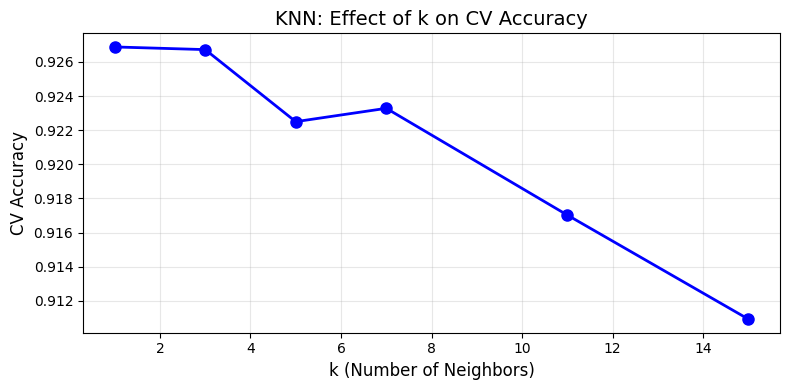

In [ ]:
print("KNN — Effect of k (n_neighbors)")
k_values = [1, 3, 5, 7, 11, 15]
k_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, weights='distance')
    scores = cross_val_score(knn, X_train_m, y_train_m, cv=cv_mnist, scoring='accuracy', n_jobs=-1)
    k_scores.append(scores.mean())
    print(f"  k={k:2d} -> CV Accuracy: {scores.mean():.4f} +/- {scores.std():.4f}")

plt.figure(figsize=(8, 4))
plt.plot(k_values, k_scores, 'bo-', linewidth=2, markersize=8)
plt.xlabel('k (Number of Neighbors)', fontsize=12)
plt.ylabel('CV Accuracy', fontsize=12)
plt.title('KNN: Effect of k on CV Accuracy', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Decision Tree — Effect of max_depth
  max_depth=   3 -> Train: 0.4998, CV: 0.4905
  max_depth=   5 -> Train: 0.6945, CV: 0.6681
  max_depth=  10 -> Train: 0.9503, CV: 0.7614
  max_depth=  15 -> Train: 0.9958, CV: 0.7595
  max_depth=  20 -> Train: 0.9995, CV: 0.7580
  max_depth=None -> Train: 1.0000, CV: 0.7580


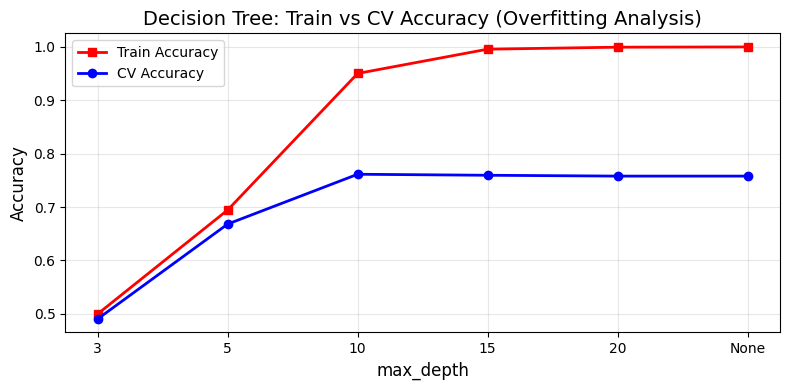

In [ ]:
print("Decision Tree — Effect of max_depth")
depths = [3, 5, 10, 15, 20, None]
dt_train_scores = []
dt_cv_scores = []
for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_scores = cross_val_score(dt, X_train_m, y_train_m, cv=cv_mnist, scoring='accuracy', n_jobs=-1)
    dt.fit(X_train_m, y_train_m)
    train_acc = accuracy_score(y_train_m, dt.predict(X_train_m))
    dt_train_scores.append(train_acc)
    dt_cv_scores.append(cv_scores.mean())
    label = str(d) if d else 'None'
    print(f"  max_depth={label:>4s} -> Train: {train_acc:.4f}, CV: {cv_scores.mean():.4f}")

x_labels = [str(d) if d else 'None' for d in depths]
plt.figure(figsize=(8, 4))
plt.plot(x_labels, dt_train_scores, 'rs-', label='Train Accuracy', linewidth=2)
plt.plot(x_labels, dt_cv_scores, 'bo-', label='CV Accuracy', linewidth=2)
plt.xlabel('max_depth', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Decision Tree: Train vs CV Accuracy (Overfitting Analysis)', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Random Forest — Effect of n_estimators
  n_estimators= 10 -> CV Accuracy: 0.8798 +/- 0.0081
  n_estimators= 50 -> CV Accuracy: 0.9200 +/- 0.0026
  n_estimators=100 -> CV Accuracy: 0.9297 +/- 0.0025
  n_estimators=200 -> CV Accuracy: 0.9316 +/- 0.0030


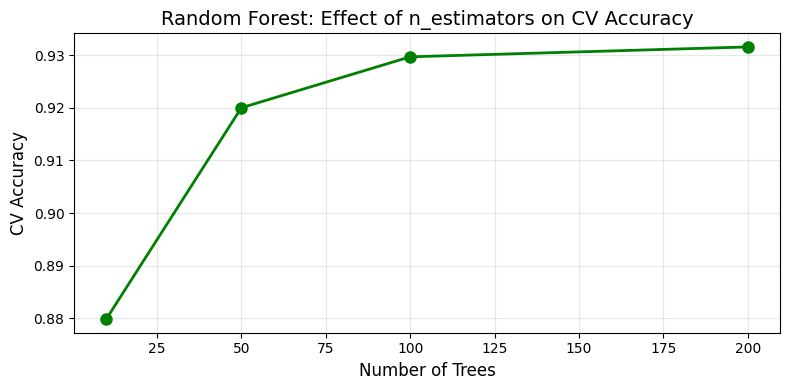

In [ ]:
print("Random Forest — Effect of n_estimators")
n_trees_list = [10, 50, 100, 200]
rf_scores = []
for n in n_trees_list:
    rf = RandomForestClassifier(n_estimators=n, max_depth=20, random_state=42, n_jobs=-1)
    scores = cross_val_score(rf, X_train_m, y_train_m, cv=cv_mnist, scoring='accuracy', n_jobs=-1)
    rf_scores.append(scores.mean())
    print(f"  n_estimators={n:3d} -> CV Accuracy: {scores.mean():.4f} +/- {scores.std():.4f}")

plt.figure(figsize=(8, 4))
plt.plot(n_trees_list, rf_scores, 'go-', linewidth=2, markersize=8)
plt.xlabel('Number of Trees', fontsize=12)
plt.ylabel('CV Accuracy', fontsize=12)
plt.title('Random Forest: Effect of n_estimators on CV Accuracy', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

ANN — Effect of hidden layer sizes
                 (64,) -> CV Accuracy: 0.9227 +/- 0.0056
                (128,) -> CV Accuracy: 0.9189 +/- 0.0034
                (256,) -> CV Accuracy: 0.9225 +/- 0.0034
             (128, 64) -> CV Accuracy: 0.9283 +/- 0.0024


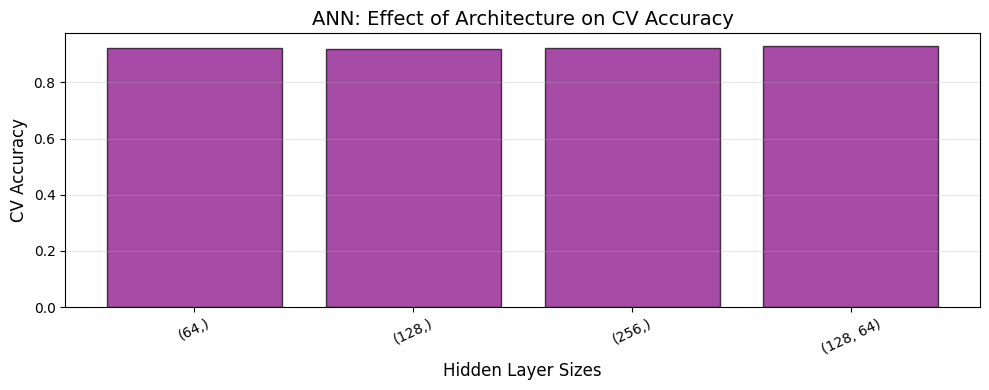

In [ ]:
print("ANN — Effect of hidden layer sizes")
architectures = [(64,), (128,), (256,), (128, 64)]
ann_scores = []
for arch in architectures:
    mlp = MLPClassifier(hidden_layer_sizes=arch, max_iter=150, random_state=42, early_stopping=True)
    scores = cross_val_score(mlp, X_train_m, y_train_m, cv=3, scoring='accuracy', n_jobs=-1)
    ann_scores.append(scores.mean())
    print(f"  {str(arch):>20s} -> CV Accuracy: {scores.mean():.4f} +/- {scores.std():.4f}")

plt.figure(figsize=(10, 4))
plt.bar(range(len(architectures)), ann_scores, color='purple', edgecolor='black', alpha=0.7)
plt.xticks(range(len(architectures)), [str(a) for a in architectures], rotation=25)
plt.xlabel('Hidden Layer Sizes', fontsize=12)
plt.ylabel('CV Accuracy', fontsize=12)
plt.title('ANN: Effect of Architecture on CV Accuracy', fontsize=14)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

### Final Best Parameters Summary

In [ ]:
print("="*60)
print("BEST HYPERPARAMETERS — URBAN LAND COVER")
print("="*60)
for name, r in uc_results.items():
    print(f"\n{name} (Test Acc: {r['test_accuracy']:.4f}, F1: {r['test_f1']:.4f}):")
    for k, v in r['best_params'].items():
        print(f"  {k}: {v}")

print("\n\n" + "="*60)
print("BEST HYPERPARAMETERS — MNIST")
print("="*60)
for name, r in mnist_results.items():
    print(f"\n{name} (Test Acc: {r['test_accuracy']:.4f}, F1: {r['test_f1']:.4f}):")
    for k, v in r['best_params'].items():
        print(f"  {k}: {v}")

BEST HYPERPARAMETERS — URBAN LAND COVER

Decision Tree (Test Acc: 0.8222, F1: 0.8200):
  criterion: gini
  max_depth: 5
  min_samples_leaf: 5
  min_samples_split: 2

Random Forest (Test Acc: 0.8444, F1: 0.8417):
  max_depth: 10
  max_features: log2
  min_samples_leaf: 1
  min_samples_split: 5
  n_estimators: 100

Naive Bayes (Test Acc: 0.8370, F1: 0.8472):
  var_smoothing: 1e-09

KNN (Test Acc: 0.8667, F1: 0.8442):
  metric: manhattan
  n_neighbors: 9
  weights: distance

ANN (MLP) (Test Acc: 0.8296, F1: 0.8308):
  activation: tanh
  alpha: 0.001
  batch_size: 32
  hidden_layer_sizes: (100, 50)
  learning_rate_init: 0.01


BEST HYPERPARAMETERS — MNIST

Decision Tree (Test Acc: 0.8119, F1: 0.8102):
  criterion: entropy
  max_depth: 10
  min_samples_leaf: 1
  min_samples_split: 2

Random Forest (Test Acc: 0.9463, F1: 0.9461):
  max_depth: 15
  max_features: sqrt
  min_samples_split: 2
  n_estimators: 200

Naive Bayes (Test Acc: 0.6956, F1: 0.6879):
  var_smoothing: 1e-05

KNN (Test Acc: 

---

## Final Discussion

### Urban Land Cover Dataset:
- **Random Forest** typically achieves the best results due to ensembling and robustness to high-dimensional data (148 features).
- **Decision Tree** alone overfits on small datasets — max_depth and min_samples_leaf pruning is critical.
- **KNN** suffers from the curse of dimensionality (148 features, only 675 samples) but standardization helps.
- **Naive Bayes** struggles with multicollinearity among GLCM texture features.
- **ANN** can perform well but needs careful regularization (alpha) given the small sample size.
- Severe **class imbalance** (some classes have only 14 samples) makes macro-F1 more informative than accuracy.

### MNIST Dataset:
- **ANN** and **KNN** dominate due to ability to capture local pixel patterns.
- **Random Forest** performs well via ensembling.
- **Naive Bayes** struggles because pixels are highly correlated.
- **Decision Tree** underfits — axis-aligned splits on 784 pixels are suboptimal.
- Common confusions: 4↔9, 3↔5↔8, 7↔1.

### Tuning Insights:
- **Grid Search** is ideal for small parameter spaces (Naive Bayes, KNN).
- **Randomized Search** is essential for large spaces (RF, ANN).
- Tuning curves reveal **diminishing returns** (RF plateaus past ~100 trees, DT overfits past max_depth=15).
- **Early stopping** in ANN prevents overfitting and saves time.
- **5-fold stratified CV** gives robust estimates, especially with imbalanced classes.